# Lab 7 : Simple Linear Regression
**Lakshay** : AP24110010677 : B.Tech CSE (AI/ML)

**Question** : Given the number of hours studied and the marks scored by 6 students, fit a **simple linear regression** line, predict the marks of a student who studies 7 hours, and evaluate the model (R², RMSE, MAE).

The problem is solved **two ways** : (1) by hand-calculation using the formula, step by step; (2) with a program (scikit-learn), and both answers are compared.

## What is Simple Linear Regression?
Regression estimates the relationship between a **dependent variable** $y$ (what we want to predict) and **independent variable(s)** $x$ (the predictors).

In **simple** linear regression there is only **one** independent variable, and the relationship is a straight line:

$$y_i = \beta_0 + \beta_1 x_i + \epsilon_i \qquad\qquad \hat y_i = \beta_0 + \beta_1 x_i$$

* $\beta_0$ : intercept (value of $y$ when $x = 0$)
* $\beta_1$ : slope (how much $y$ changes when $x$ goes up by 1)
* $\epsilon_i$ : error term (assumed normally distributed)

The **best-fit line** is the one that minimises the sum of squared errors $\sum (y_i - \hat y_i)^2$ (**least squares**). Differentiating with respect to $\beta_0$ and $\beta_1$ and setting to zero gives:

$$\beta_1 = \frac{\sum (x_i-\bar x)(y_i-\bar y)}{\sum (x_i-\bar x)^2} \qquad\qquad \beta_0 = \bar y - \beta_1 \bar x$$

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

np.random.seed(77)            # last two digits of roll number

## Dataset
Hours studied ($x$) and marks scored ($y$) by 6 students.

In [2]:
df = pd.DataFrame({"hours": [1, 2, 3, 4, 5, 6],
                   "marks": [40, 45, 55, 60, 70, 72]})
x = df["hours"].values
y = df["marks"].values
n = len(x)
df

,hours,marks
0,1,40
1,2,45
2,3,55
3,4,60
4,5,70
5,6,72


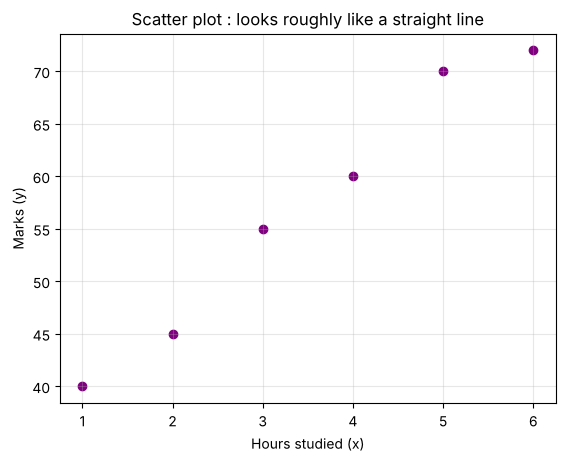

In [3]:
plt.scatter(x, y, color="purple")
plt.xlabel("Hours studied (x)"); plt.ylabel("Marks (y)")
plt.title("Scatter plot : looks roughly like a straight line")
plt.grid(alpha=0.3); plt.show()

---
## Part 1 : Calculation (step by step using the formula)
### Step 1 : means of x and y

In [4]:
x_bar, y_bar = x.mean(), y.mean()
print(f"Σx = {x.sum()},  x̄ = {x.sum()}/{n} = {x_bar}")
print(f"Σy = {y.sum()},  ȳ = {y.sum()}/{n} = {y_bar}")

Σx = 21,  x̄ = 21/6 = 3.5
Σy = 342,  ȳ = 342/6 = 57.0


### Step 2 : deviation table

In [5]:
table = pd.DataFrame({"x": x, "y": y,
                      "x - x̄": x - x_bar,
                      "y - ȳ": y - y_bar,
                      "(x - x̄)(y - ȳ)": (x - x_bar) * (y - y_bar),
                      "(x - x̄)²": (x - x_bar) ** 2})
print(table.to_string(index=False))
print("\nΣ(x - x̄)(y - ȳ) =", table["(x - x̄)(y - ȳ)"].sum())
print("Σ(x - x̄)²       =", table["(x - x̄)²"].sum())

 x  y  x - x̄  y - ȳ  (x - x̄)(y - ȳ)  (x - x̄)²
 1 40    -2.5  -17.0             42.5       6.25
 2 45    -1.5  -12.0             18.0       2.25
 3 55    -0.5   -2.0              1.0       0.25
 4 60     0.5    3.0              1.5       0.25
 5 70     1.5   13.0             19.5       2.25
 6 72     2.5   15.0             37.5       6.25

Σ(x - x̄)(y - ȳ) = 120.0
Σ(x - x̄)²       = 17.5


### Step 3 : slope β₁ and intercept β₀

In [6]:
Sxy = table["(x - x̄)(y - ȳ)"].sum()
Sxx = table["(x - x̄)²"].sum()

b1 = Sxy / Sxx
b0 = y_bar - b1 * x_bar
print(f"β₁ = {Sxy} / {Sxx} = {b1:.4f}")
print(f"β₀ = ȳ - β₁x̄ = {y_bar} - {b1:.4f} × {x_bar} = {b0:.4f}")
print(f"\nRegression line :  ŷ = {b0:.4f} + {b1:.4f}·x")

β₁ = 120.0 / 17.5 = 6.8571
β₀ = ȳ - β₁x̄ = 57.0 - 6.8571 × 3.5 = 33.0000

Regression line :  ŷ = 33.0000 + 6.8571·x


### Step 4 : prediction for a student who studies 7 hours

In [7]:
print(f"ŷ(7) = {b0:.4f} + {b1:.4f} × 7 = {b0 + b1 * 7:.2f} marks")

ŷ(7) = 33.0000 + 6.8571 × 7 = 81.00 marks


---
## Part 2 : Program (scikit-learn)
`LinearRegression` finds the same least-squares line automatically.

In [8]:
model = LinearRegression()
model.fit(x.reshape(-1, 1), y)          # sklearn needs x as a column (2-D)

print(f"β₀ (sklearn) = {model.intercept_:.4f}   |   β₀ (by hand) = {b0:.4f}")
print(f"β₁ (sklearn) = {model.coef_[0]:.4f}   |   β₁ (by hand) = {b1:.4f}")
print(f"Prediction for 7 hours (sklearn) = {model.predict([[7]])[0]:.2f}")

β₀ (sklearn) = 33.0000   |   β₀ (by hand) = 33.0000
β₁ (sklearn) = 6.8571   |   β₁ (by hand) = 6.8571
Prediction for 7 hours (sklearn) = 81.00


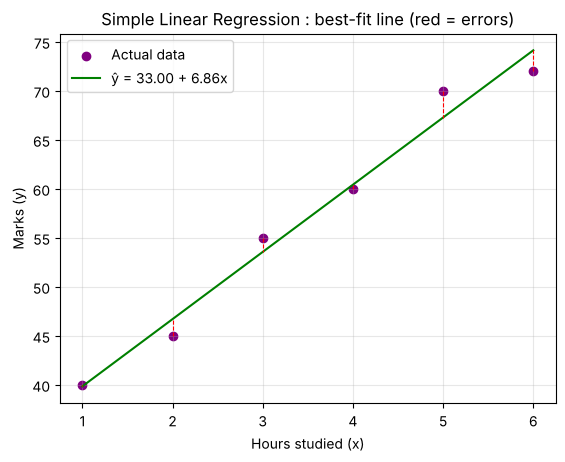

In [9]:
y_hat = model.predict(x.reshape(-1, 1))

plt.scatter(x, y, color="purple", label="Actual data")
plt.plot(x, y_hat, color="green", label=f"ŷ = {b0:.2f} + {b1:.2f}x")
for xi, yi, yh in zip(x, y, y_hat):                       # residuals
    plt.plot([xi, xi], [yi, yh], "r--", lw=0.8)
plt.xlabel("Hours studied (x)"); plt.ylabel("Marks (y)")
plt.title("Simple Linear Regression : best-fit line (red = errors)")
plt.legend(); plt.grid(alpha=0.3); plt.show()

---
## Evaluation
### Theory : how good is the model?
* **R² (coefficient of determination)** : what fraction of the variation in $y$ the model explains. Closer to **1** is better.
$$R^2 = 1 - \frac{SSE}{SST} = \frac{SSR}{SST}, \quad SSE=\sum(y_i-\hat y_i)^2,\; SST=\sum(y_i-\bar y)^2,\; SSR=\sum(\hat y_i-\bar y)^2$$
* **RMSE** : $\sqrt{\frac{1}{n}\sum(y_i-\hat y_i)^2}$ : average size of the error, in the same unit as $y$. Lower is better.
* **MAE** : $\frac{1}{n}\sum|y_i-\hat y_i|$ : average absolute error. Lower is better.

### Calculation

In [10]:
ev = pd.DataFrame({"y": y, "ŷ": y_hat.round(3),
                   "e = y - ŷ": (y - y_hat).round(3),
                   "e²": ((y - y_hat) ** 2).round(3),
                   "|e|": np.abs(y - y_hat).round(3),
                   "(y - ȳ)²": (y - y_bar) ** 2})
print(ev.to_string(index=False))

SSE = ((y - y_hat) ** 2).sum()
SST = ((y - y_bar) ** 2).sum()
print(f"\nSSE = {SSE:.4f},  SST = {SST:.4f}")
print(f"R²   = 1 - SSE/SST = {1 - SSE / SST:.4f}")
print(f"RMSE = √(SSE/n)    = {np.sqrt(SSE / n):.4f}")
print(f"MAE  = Σ|e| / n    = {np.abs(y - y_hat).sum() / n:.4f}")

 y      ŷ  e = y - ŷ    e²   |e|  (y - ȳ)²
40 39.857      0.143 0.020 0.143     289.0
45 46.714     -1.714 2.939 1.714     144.0
55 53.571      1.429 2.041 1.429       4.0
60 60.429     -0.429 0.184 0.429       9.0
70 67.286      2.714 7.367 2.714     169.0
72 74.143     -2.143 4.592 2.143     225.0

SSE = 17.1429,  SST = 840.0000
R²   = 1 - SSE/SST = 0.9796
RMSE = √(SSE/n)    = 1.6903
MAE  = Σ|e| / n    = 1.4286


### Program (sklearn metrics)

In [11]:
print(f"R²   = {r2_score(y, y_hat):.4f}")
print(f"RMSE = {np.sqrt(mean_squared_error(y, y_hat)):.4f}")
print(f"MAE  = {mean_absolute_error(y, y_hat):.4f}")

R²   = 0.9796
RMSE = 1.6903
MAE  = 1.4286


### Residual plot
If the line fits well, residuals are scattered randomly around 0 with no pattern.

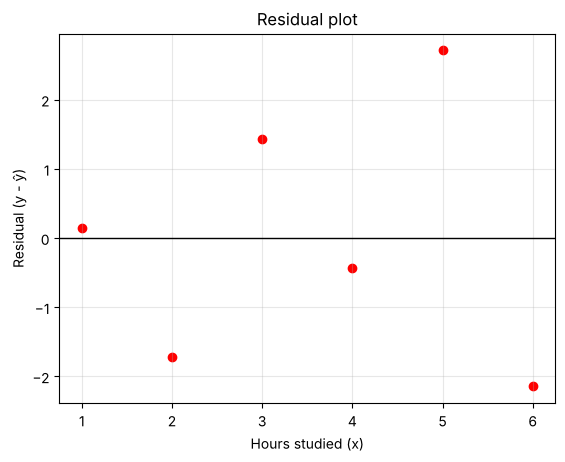

In [12]:
plt.scatter(x, y - y_hat, color="red")
plt.axhline(0, color="black", lw=1)
plt.xlabel("Hours studied (x)"); plt.ylabel("Residual (y - ŷ)")
plt.title("Residual plot"); plt.grid(alpha=0.3); plt.show()

## Conclusion
* The hand calculation and the scikit-learn program give the **same** line: $\hat y = 33 + 6.857x$.
* Each extra hour of study adds about **6.86 marks**; a student who studies 7 hours is predicted to score **81 marks**.
* **R² ≈ 0.98** : the line explains about 98 % of the variation in marks, so it is a very good fit. RMSE ≈ 1.69 and MAE ≈ 1.43 marks, and the residuals show no pattern.